# Assignment 2 – Task 1: Gradient Domain Editing

## 1. Bài toán và dữ liệu

**Mục tiêu:** tách cô gái cầm ô từ `Input/anh_nhan_vat.jpg`, đặt gần bên trái `Input/nen.jpg`, với chiều cao cơ thể xấp xỉ cô gái có sẵn bên phải. Ghép trong miền gradient để hòa màu và biên với nền.

- **Ảnh nền:** phong cảnh bầu trời, cây và mặt nước, kích thước 650 × 400.
- **Ảnh nguồn:** cô gái tóc hồng, váy trắng, cầm ô trong khung cảnh ban đêm.
- **Mask:** đa giác thủ công cho cơ thể và tán ô, cùng nét vẽ cho cán ô; bỏ nền đêm và phần phản chiếu dưới chân.
- **Bố cục:** chiều cao cơ thể khoảng 120 pixel (không tính ô), chân ở y ≈ 356 và nhân vật nằm trong phần tư bên trái.
- **So sánh:** ghép trực tiếp, Poisson tự viết, screened Poisson và OpenCV `seamlessClone(NORMAL_CLONE)`.

**Cách chạy:** chọn kernel Python 3 và **Run All**. Cần `numpy scipy pillow matplotlib ipython opencv-python`; nếu thiếu, chạy `%pip install numpy scipy pillow matplotlib ipython opencv-python` trong một cell riêng. Kết quả được lưu vào `Output/` cạnh notebook. Thuật toán không tự tạo bóng đổ hoặc phản chiếu mới.


Nguồn: (1345, 700, 3); nền: (400, 650, 3) (H, W, RGB)


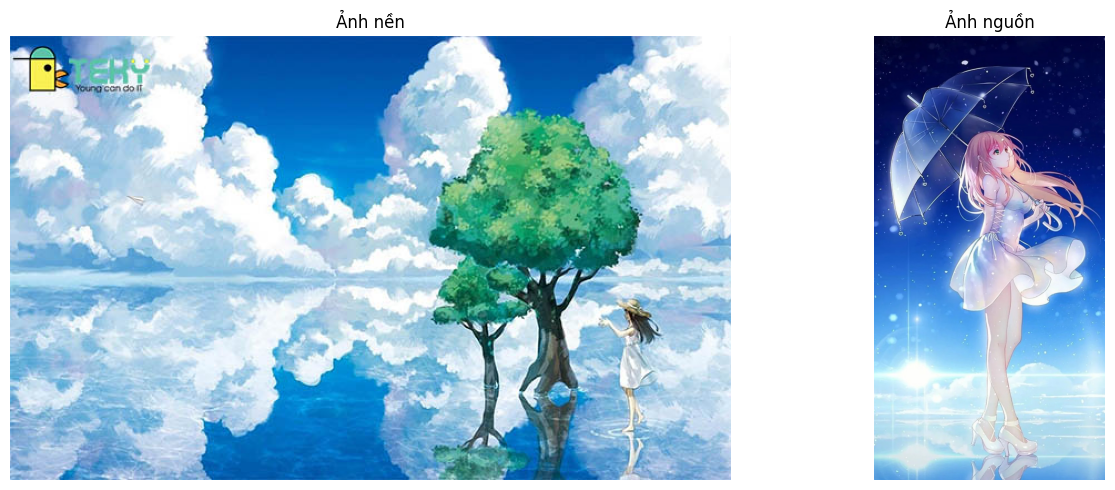

In [1]:
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scipy import sparse
from scipy.ndimage import binary_dilation
from scipy.sparse.linalg import splu
from IPython.display import display, Markdown

# Hỗ trợ mở Jupyter từ thư mục Task1, Assignment-2 hoặc gốc repository.
candidates = [Path.cwd(), Path.cwd() / 'Task1',
              Path.cwd() / 'Assignment-2' / 'Task1']
BASE_DIR = next((p for p in candidates
                 if (p / 'Input' / 'anh_nhan_vat.jpg').is_file()
                 and (p / 'Input' / 'nen.jpg').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('Mở notebook từ Task1, Assignment-2 hoặc gốc repository.')
OUT_DIR = BASE_DIR / 'Output'
OUT_DIR.mkdir(exist_ok=True)

source = np.asarray(Image.open(BASE_DIR / 'Input' / 'anh_nhan_vat.jpg').convert('RGB'))
background = np.asarray(Image.open(BASE_DIR / 'Input' / 'nen.jpg').convert('RGB'))
print(f'Nguồn: {source.shape}; nền: {background.shape} (H, W, RGB)')

def show_images(images, titles, figsize=(14, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for ax, img, title in zip(axes.flat, images, titles):
        ax.imshow(img, cmap='gray' if img.ndim == 2 else None,
                  vmin=0 if img.ndim == 2 else None,
                  vmax=255 if img.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    return fig

fig = show_images([background, source], ['Ảnh nền', 'Ảnh nguồn'])
plt.show()

## 2. Nguyên lý Gradient Domain Editing

Ghép trực tiếp chép giá trị RGB từ nguồn sang nền. Khi hai ảnh khác ánh sáng/màu, đường biên có thể bị lộ. Gradient Domain Editing chuyển sang ràng buộc **chênh lệch giữa các pixel lân cận**: giữ gradient của nguồn và dùng màu nền làm điều kiện biên.

Gọi $g$ là ảnh nguồn sau biến đổi vị trí/kích thước, $t$ là ảnh nền, $\Omega$ là vùng mask và $f$ là kết quả cần tìm. Với từng kênh RGB, giải:

$$\min_f \int_\Omega \|\nabla f-\nabla g\|^2\,d\mathbf{x},
\qquad f|_{\partial\Omega}=t|_{\partial\Omega}.$$

Phương trình Euler–Lagrange tương ứng là **phương trình Poisson**:

$$\Delta f=\Delta g \quad\text{trong }\Omega.$$

Trên lưới 4 láng giềng $N_p$, đặt $v_{pq}=g_p-g_q$. Dạng rời rạc dùng trong notebook là:

$$4f_p-\sum_{q\in N_p\cap\Omega}f_q
=\sum_{q\in N_p}v_{pq}+\sum_{q\in N_p\setminus\Omega}t_q.$$

Mỗi pixel trong mask tương ứng một ẩn: đường chéo ma trận $A$ bằng 4, phần tử ứng với láng giềng trong mask bằng $-1$. Láng giềng ngoài mask đóng góp màu nền vào vế phải $b$. Giải $AX=B$ cho ba kênh bằng cùng một phân rã LU thưa. Các pixel ngoài mask giữ nguyên ảnh nền. Mask được đặt cách biên ảnh ít nhất một pixel để luôn có đủ 4 láng giềng.

**Lưu ý:** thuật toán giữ cấu trúc gradient theo nghĩa bình phương tối thiểu, không đảm bảo giữ nguyên màu tuyệt đối. Đặc biệt, váy trắng và vùng màu phẳng có thể nhận sắc xanh của nền. Điều kiện biên cố định các pixel **ngoài** mask; pixel trong cùng sát biên không bị ép bằng pixel nền cùng vị trí.

Tham khảo: Pérez, Gangnet & Blake (2003), [Poisson Image Editing](https://www.cs.jhu.edu/~misha/Fall07/Papers/Perez03.pdf), ACM TOG 22(3), 313–318. Phần dưới tự xây dựng hệ tuyến tính, không gọi hàm ghép ảnh có sẵn.

## 3. Tạo mask thủ công và xác định vị trí

Mask được vẽ lại cho ảnh **700 × 1345**, gồm đường bao cơ thể, tán ô và cán ô. Các tọa độ chỉ dành cho ảnh nguồn này; khi thay bằng một ảnh khác phải tạo lại mask. Ô có tính trong suốt nhưng mask ở đây vẫn là nhị phân: đây là xấp xỉ, không phải alpha matting.

Chiều cao cơ thể được đo từ đỉnh tóc (y ≈ 290) tới đế giày (y ≈ 1279). Chọn `TARGET_PERSON_HEIGHT = 120`, tương đương cô gái bên phải trong nền (từ mũ tới chân khoảng y = 238…358). Kích thước toàn ảnh nguồn được suy ra từ cùng tỷ lệ để không bóp méo nhân vật. Tán ô vươn cao hơn nên không dùng chiều cao toàn mask để cân bằng kích thước hai cô gái.

`PASTE_LEFT = 80` đặt nhân vật gần bên trái; `FOOT_Y = 356` đặt chân ngang mức cô gái bên phải. Resize ảnh bằng Lanczos, mask bằng nearest neighbor, rồi thêm viền đệm cho việc tính gradient. Mask thủ công có thể còn sót nền ở các khe tóc, tay và cán ô.


Sau resize, nới mask thêm 4 pixel để giữ cả gradient tại đường bao và tạo vùng chuyển tiếp quanh nhân vật. Điều này cũng hạn chế mất chi tiết mảnh khi OpenCV tiền xử lý mask. Cả hai bộ giải nhận chính xác cùng mask đã nới; phần mở rộng lấy màu/gradient của ảnh nguồn, không phải màu nền.

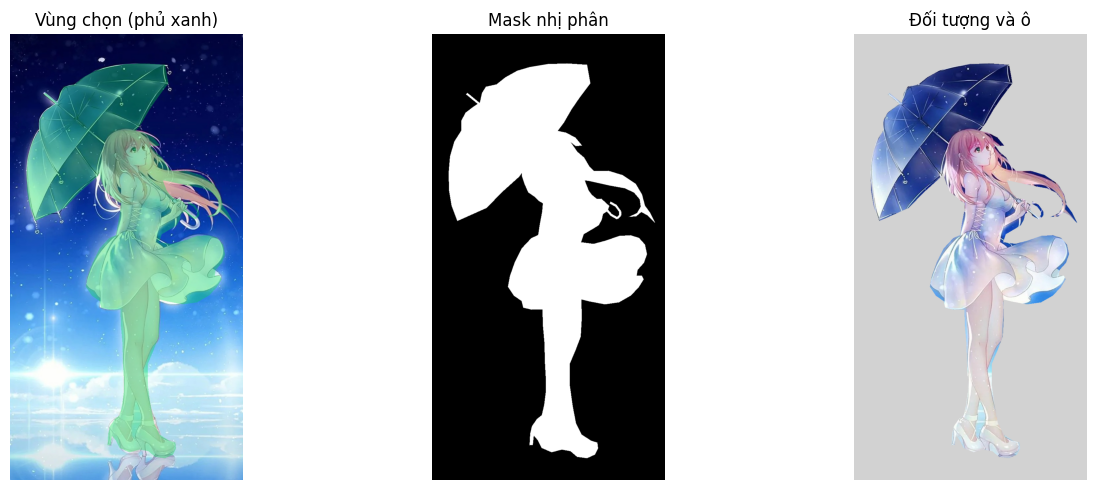

Ảnh nguồn resize: (85, 163); cơ thể ≈ 119.9 pixel; vị trí góc ảnh: (80, 201); chân y ≈ 356; 6,850 ẩn.


In [2]:
# Tọa độ tham chiếu trên ảnh nguồn 700 × 1345: mask cơ thể + ô.
body_ref = np.array([
    (284,342),(293,319),(315,296),(343,290),(372,293),(401,299),
    (430,314),(450,338),(432,340),(415,327),(436,357),(456,374),
    (472,401),(486,415),(529,414),(572,427),(611,453),(630,485),
    (639,519),(655,541),(669,570),(647,548),(628,538),(613,551),
    (591,553),(616,541),(627,522),(624,500),(607,480),(580,467),
    (531,458),(473,445),(458,443),(470,474),(489,499),(508,498),
    (522,511),(532,520),(526,536),(513,544),(509,562),(500,578),
    (484,588),(455,605),(447,629),(485,634),(519,625),(563,610),
    (596,608),(621,616),(639,636),(645,665),(636,691),(617,712),
    (614,730),(630,730),(635,741),(620,765),(596,790),(561,810),
    (519,816),(472,807),(448,801),(449,858),(446,913),(430,955),
    (413,995),(413,1059),(422,1123),(432,1175),(449,1208),
    (477,1226),(496,1232),(498,1249),(489,1268),(465,1279),
    (436,1275),(416,1258),(390,1253),(359,1261),(329,1248),
    (317,1224),(305,1210),(302,1239),(293,1240),(295,1205),
    (300,1183),(315,1161),(330,1149),(337,1118),(342,1078),
    (342,1040),(339,987),(338,934),(333,878),(332,831),(299,832),
    (274,826),(269,806),(246,790),(228,763),(234,731),(249,688),
    (269,648),(298,617),(319,607),(324,574),(331,537),(333,512),
    (321,505),(309,493),(289,479),(278,454),(270,430),(268,392)
], dtype=float)
umbrella_ref = np.array([
    (465,95),(475,151),(444,192),(418,230),(395,270),(371,302),
    (326,350),(292,389),(261,432),(211,477),(163,526),(76,565),
    (59,520),(51,473),(50,420),(54,371),(67,326),(88,293),
    (88,263),(101,239),(126,220),(144,208),(150,180),(162,161),
    (194,154),(220,133),(256,113),(293,102),(347,93),(405,91)
], dtype=float)
reference_scale = np.array([source.shape[1] / 700, source.shape[0] / 1345])
mask_pil = Image.new('L', (source.shape[1], source.shape[0]), 0)
draw = ImageDraw.Draw(mask_pil)
for polygon_ref in [body_ref, umbrella_ref]:
    draw.polygon([tuple(pt) for pt in polygon_ref * reference_scale], fill=255)
shaft_ref = np.array([(104,182),(511,516),(538,547),(556,557),
                      (565,548),(565,537),(552,519),(535,510)])
draw.line([tuple(pt) for pt in shaft_ref * reference_scale], fill=255,
          width=max(1, round(7 * reference_scale.mean())))
source_mask = np.asarray(mask_pil)

TARGET_PERSON_HEIGHT = 120  # Chiều cao từ đỉnh tóc tới đế giày, không tính ô.
PASTE_LEFT = 80
FOOT_Y = 356
head_y, foot_y = 290 * reference_scale[1], 1279 * reference_scale[1]
resize_scale = TARGET_PERSON_HEIGHT / (foot_y - head_y)
TARGET_HEIGHT = round(source.shape[0] * resize_scale)
new_size = (round(source.shape[1] * resize_scale), TARGET_HEIGHT)
# Dùng tỷ lệ thực sau khi làm tròn kích thước resize để canh bàn chân.
PASTE_XY = (PASTE_LEFT, FOOT_Y - round(foot_y * TARGET_HEIGHT / source.shape[0]))
small_source = np.asarray(Image.fromarray(source).resize(new_size, Image.Resampling.LANCZOS))
small_mask = np.asarray(mask_pil.resize(new_size, Image.Resampling.NEAREST)) > 0

PAD = 8
patch = np.pad(small_source, ((PAD, PAD), (PAD, PAD), (0, 0)), mode='edge')
MASK_MARGIN = 4
patch_mask = binary_dilation(np.pad(small_mask, PAD, constant_values=False),
                             structure=np.ones((3, 3), dtype=bool), iterations=MASK_MARGIN)
x0, y0 = PASTE_XY[0] - PAD, PASTE_XY[1] - PAD
ph, pw = patch_mask.shape
H, W = background.shape[:2]
if not (0 <= x0 and 0 <= y0 and x0 + pw <= W and y0 + ph <= H):
    raise ValueError('Patch vượt khỏi nền: giảm kích thước hoặc đổi vị trí.')
source_canvas = background.astype(np.float64).copy()
source_canvas[y0:y0+ph, x0:x0+pw] = patch
mask = np.zeros((H, W), dtype=bool)
mask[y0:y0+ph, x0:x0+pw] = patch_mask
assert mask.any() and not (mask[0].any() or mask[-1].any()
                          or mask[:,0].any() or mask[:,-1].any())

preview = source.copy()
preview[source_mask > 0] = np.round(
    0.65 * preview[source_mask > 0] + 0.35 * np.array([0, 220, 80])
).astype(np.uint8)
cutout = np.full_like(source, 210)
cutout[source_mask > 0] = source[source_mask > 0]
fig = show_images([preview, source_mask, cutout],
                  ['Vùng chọn (phủ xanh)', 'Mask nhị phân', 'Đối tượng và ô'])
fig.savefig(OUT_DIR / '01_mask_preview.png', dpi=130, bbox_inches='tight')
plt.show()
actual_person_height = (foot_y - head_y) * TARGET_HEIGHT / source.shape[0]
print(f'Ảnh nguồn resize: {new_size}; cơ thể ≈ {actual_person_height:.1f} pixel; '
      f'vị trí góc ảnh: {PASTE_XY}; chân y ≈ {FOOT_Y}; {mask.sum():,} ẩn.')

## 4. Ghép trực tiếp và hiện thực bộ giải Poisson

1. Đặt ảnh nguồn và mask vào hệ tọa độ ảnh nền.
2. Với ghép trực tiếp, thay pixel nền trong mask bằng pixel nguồn.
3. Đánh số các pixel trong mask; xây dựng ma trận thưa $A$ và vế phải $B$ theo công thức ở mục 2.
4. Phân rã ma trận một lần, giải đồng thời ba kênh RGB.
5. Đưa nghiệm vào vùng mask, giới hạn RGB về `[0, 255]` rồi lưu ảnh. Tính sai số hệ tuyến tính **trước** bước giới hạn và làm tròn.

Để khảo sát hiện tượng đổi màu, hàm còn hỗ trợ **screened Poisson** (mở rộng): thêm $\lambda\sum_{p\in\Omega}\|f_p-g_p\|^2$ vào năng lượng rời rạc, tương đương $(A+\lambda I)X=B+\lambda G$. Với $\lambda=0$ ta có Poisson chuẩn. Với $\lambda>0$, kết quả ưu tiên giữ màu nguồn hơn nhưng có thể lộ biên hơn. Đây là tham số thử nghiệm, không phải giá trị tối ưu cho mọi ảnh.

In [3]:
direct = background.copy()
direct[mask] = source_canvas[mask].astype(np.uint8)

def poisson_blend(src, dst, region, color_weight=0.0):
    """Tự giải Poisson chuẩn / screened Poisson trên miền mask, RGB float64."""
    src = np.asarray(src, dtype=np.float64)
    dst = np.asarray(dst, dtype=np.float64)
    region = np.asarray(region, dtype=bool)
    if src.shape != dst.shape or region.shape != dst.shape[:2]:
        raise ValueError('Nguồn, nền và mask phải cùng hệ tọa độ.')
    if color_weight < 0 or not np.isfinite(color_weight):
        raise ValueError('color_weight phải hữu hạn và không âm.')
    if not region.any():
        raise ValueError('Mask rỗng.')
    if (region[0].any() or region[-1].any()
            or region[:,0].any() or region[:,-1].any()):
        raise ValueError('Mask phải cách biên ảnh ít nhất một pixel.')

    start = perf_counter()
    ys, xs = np.nonzero(region)
    n = len(ys)
    ids = np.full(region.shape, -1, dtype=np.int32)
    ids[ys, xs] = np.arange(n)
    rows = [np.arange(n)]
    cols = [np.arange(n)]
    values = [np.full(n, 4.0 + color_weight)]
    rhs = color_weight * src[ys, xs].copy()

    for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        ny, nx = ys + dy, xs + dx
        # Gradient nguồn v_pq = g_p - g_q (float, tránh tràn số uint8).
        rhs += src[ys, xs] - src[ny, nx]
        inside = region[ny, nx]
        rows.append(np.flatnonzero(inside))
        cols.append(ids[ny[inside], nx[inside]])
        values.append(-np.ones(np.count_nonzero(inside)))
        # Điều kiện Dirichlet từ ảnh nền cho láng giềng ngoài miền.
        rhs[~inside] += dst[ny[~inside], nx[~inside]]

    A = sparse.coo_matrix((np.concatenate(values),
                           (np.concatenate(rows), np.concatenate(cols))),
                          shape=(n, n)).tocsc()
    factor = splu(A)
    solution = factor.solve(rhs)
    relative_residual = np.linalg.norm(A @ solution - rhs) / max(np.linalg.norm(rhs), 1e-12)
    if not np.isfinite(solution).all():
        raise RuntimeError('Nghiệm chứa NaN/Inf.')
    result_float = dst.copy()
    result_float[ys, xs] = solution
    result = np.rint(np.clip(result_float, 0, 255)).astype(np.uint8)
    diagnostics = {
        'unknowns': n, 'nonzeros': int(A.nnz),
        'relative_residual': float(relative_residual),
        'clipped_channel_percent': float(100 * np.mean((solution < 0) | (solution > 255))),
        'seconds': float(perf_counter() - start),
    }
    return result, diagnostics

poisson, poisson_info = poisson_blend(source_canvas, background, mask)
COLOR_WEIGHT = 0.02
screened, screened_info = poisson_blend(source_canvas, background, mask, COLOR_WEIGHT)
for name, info in [('Poisson chuẩn', poisson_info), ('Screened Poisson', screened_info)]:
    print(f'{name}: {info["unknowns"]:,} ẩn, {info["nonzeros"]:,} phần tử khác 0; '
          f'residual = {info["relative_residual"]:.2e}; '
          f'giới hạn màu = {info["clipped_channel_percent"]:.2f}%; '
          f'{info["seconds"]:.3f} s')

Poisson chuẩn: 6,850 ẩn, 33,688 phần tử khác 0; residual = 1.61e-15; giới hạn màu = 40.47%; 0.068 s
Screened Poisson: 6,850 ẩn, 33,688 phần tử khác 0; residual = 1.24e-15; giới hạn màu = 6.40%; 0.056 s


### 4.1. Đối chiếu bằng Poisson của OpenCV

Cell dưới dùng `cv2.seamlessClone(..., cv2.NORMAL_CLONE)` với cùng nguồn, nền, mask và vị trí như Poisson tự viết (λ = 0). Đổi RGB sang BGR khi gọi OpenCV, rồi đổi lại. Tâm truyền vào được tính từ **bounding box của mask khác 0**, đúng với cách đặt vùng ghép của `NORMAL_CLONE`.

Hiển thị hai ảnh và bản đồ sai khác; MAE chỉ tính trong mask để tránh việc nền chiếm phần lớn ảnh làm sai khác trông nhỏ giả tạo. Hai ảnh có thể khác do OpenCV xử lý/erosion mask, tính gradient và giải trên ROI nội bộ khác hệ 4 láng giềng trên mask của ta. Không đặt điều kiện phải giống từng pixel. Các kiểm tra ở mục 5.1 mới trực tiếp xác nhận bộ giải thỏa bài toán đã xây dựng.

Tham khảo: [OpenCV 4.11 – Seamless Cloning](https://docs.opencv.org/4.11.0/df/da0/group__photo__clone.html) và [mã nguồn seamlessClone](https://github.com/opencv/opencv/blob/4.11.0/modules/photo/src/seamless_cloning.cpp).


OpenCV 4.11.0, tâm ghép (123, 284), 0.041 s
Sai khác RGB trong mask (tự viết so với OpenCV): MAE = 8.957; max = 170 / 255


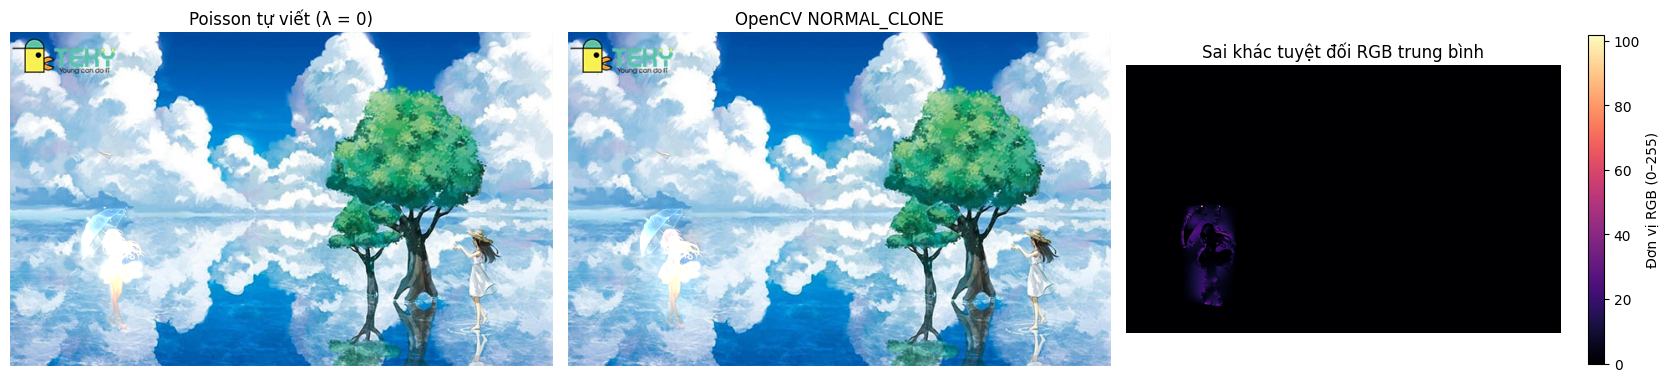

In [4]:
import cv2  # Nếu thiếu: %pip install opencv-python

mask_u8 = mask.astype(np.uint8) * 255
bx, by, bw, bh = cv2.boundingRect(mask_u8)
clone_center = (bx + bw // 2, by + bh // 2)
start_cv = perf_counter()
opencv_bgr = cv2.seamlessClone(
    cv2.cvtColor(source_canvas.astype(np.uint8), cv2.COLOR_RGB2BGR),
    cv2.cvtColor(background, cv2.COLOR_RGB2BGR),
    mask_u8.copy(), clone_center, cv2.NORMAL_CLONE,
)
opencv_poisson = cv2.cvtColor(opencv_bgr, cv2.COLOR_BGR2RGB)
opencv_seconds = perf_counter() - start_cv
assert opencv_poisson.shape == background.shape and opencv_poisson.dtype == np.uint8

abs_difference = np.abs(poisson.astype(np.float64) - opencv_poisson.astype(np.float64))
opencv_comparison = {
    'version': cv2.__version__, 'mode': 'NORMAL_CLONE',
    'center_xy': list(clone_center),
    'mask_rgb_mae': float(abs_difference[mask].mean()),
    'mask_rgb_max_difference': float(abs_difference[mask].max()),
    'seconds': float(opencv_seconds),
}
print(f'OpenCV {cv2.__version__}, tâm ghép {clone_center}, {opencv_seconds:.3f} s')
print(f'Sai khác RGB trong mask (tự viết so với OpenCV): '
      f'MAE = {opencv_comparison["mask_rgb_mae"]:.3f}; '
      f'max = {opencv_comparison["mask_rgb_max_difference"]:.0f} / 255')

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(poisson)
axes[0].set_title('Poisson tự viết (λ = 0)')
axes[1].imshow(opencv_poisson)
axes[1].set_title('OpenCV NORMAL_CLONE')
heat = axes[2].imshow(abs_difference.mean(axis=2), cmap='magma', vmin=0,
                      vmax=max(1.0, abs_difference.mean(axis=2).max()))
axes[2].set_title('Sai khác tuyệt đối RGB trung bình')
for ax in axes:
    ax.axis('off')
fig.colorbar(heat, ax=axes[2], shrink=0.7, label='Đơn vị RGB (0–255)')
fig.tight_layout()
fig.savefig(OUT_DIR / '04_opencv_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. So sánh kết quả

Bốn kết quả dùng chung ảnh nguồn, tỷ lệ, vị trí và mask đầu vào. Hình toàn cảnh cho thấy nhân vật nằm gần bên trái, nhỏ tương đương cô gái bên phải. Hình phóng to dùng cùng cửa sổ bao nhân vật và ô để quan sát biên và chuyển màu. OpenCV có tiền xử lý mask và cách giải nội bộ khác, nên ảnh của nó không nhất thiết trùng từng pixel với bộ giải tự viết.


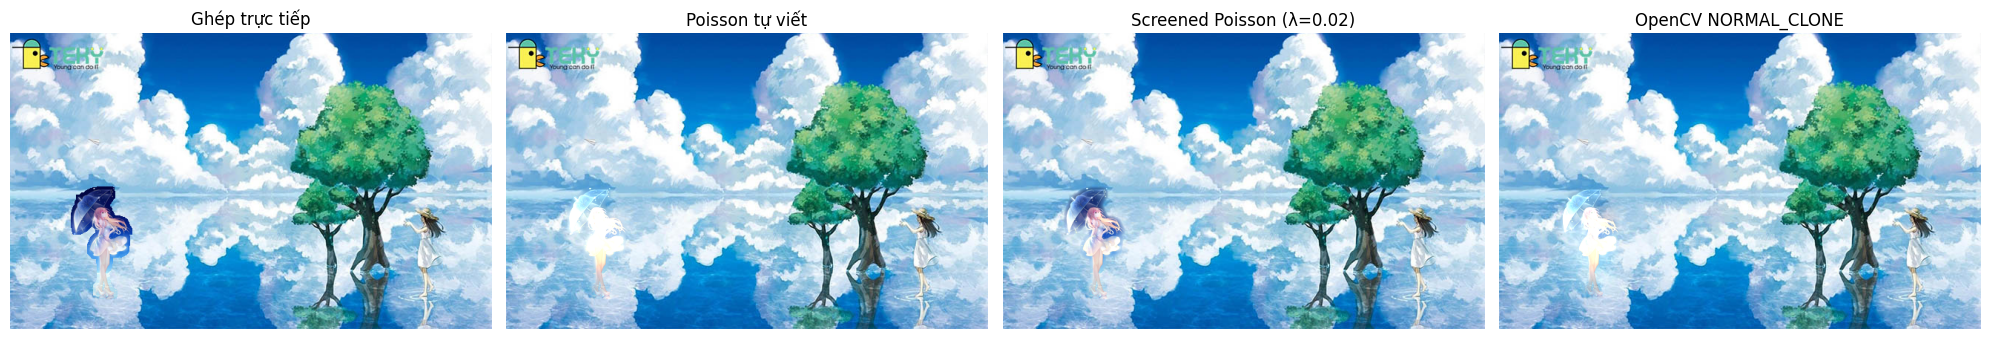

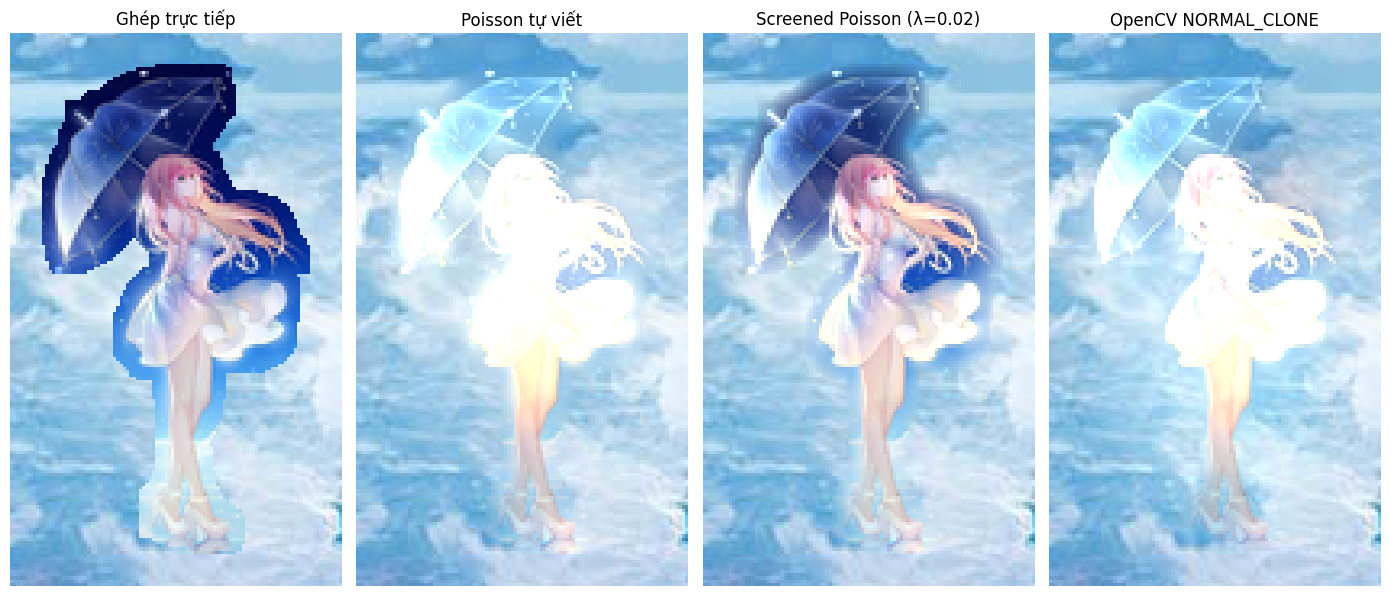

In [5]:
results = [direct, poisson, screened, opencv_poisson]
titles = ['Ghép trực tiếp', 'Poisson tự viết', f'Screened Poisson (λ={COLOR_WEIGHT})', 'OpenCV NORMAL_CLONE']
fig = show_images(results, titles, figsize=(20, 5))
fig.savefig(OUT_DIR / '02_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

# Phóng to toàn bộ đối tượng theo cùng một cửa sổ.
my, mx = np.nonzero(mask)
zx0, zx1 = max(0, mx.min() - 10), min(W, mx.max() + 11)
zy0, zy1 = max(0, my.min() - 10), min(H, my.max() + 11)
fig = show_images([img[zy0:zy1, zx0:zx1] for img in results], titles, figsize=(14, 7))
fig.savefig(OUT_DIR / '03_boundary_zoom.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.1. Chỉ số kiểm tra và ý nghĩa

Không có ảnh ghép chuẩn (ground truth), nên không dùng PSNR/SSIM để kết luận chất lượng. Hai chỉ số mô tả dưới đây tính trên RGB thang 0–255:

- **Chênh lệch RGB qua biên:** trung bình $|f_p-t_q|$ với $p$ trong mask, $q$ ngoài mask và là láng giềng 4 hướng. Giá trị thấp cho biết độ nhảy màu qua biên nhỏ hơn, nhưng một cạnh thật của nhân vật cũng có thể cần độ nhảy lớn.
- **Sai khác gradient nội vùng:** trung bình $|(f_p-f_q)-(g_p-g_q)|$ trên các cạnh nằm hoàn toàn trong mask. Ghép trực tiếp có giá trị 0 theo định nghĩa; Poisson có thể thay đổi gradient để thỏa điều kiện biên. Đây không phải thước đo độ tự nhiên.

Residual của bộ giải kiểm tra tính đúng của hệ phương trình, không đo chất lượng thị giác. Việc clip/làm tròn RGB có thể làm ảnh xuất ra khác nghiệm liên tục.

In [6]:
def comparison_metrics(img, src, region):
    img = img.astype(np.float64)
    src = src.astype(np.float64)
    ys, xs = np.nonzero(region)
    boundary_values, interior_errors = [], []
    for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
        ny, nx = ys + dy, xs + dx
        inside = region[ny, nx]
        if (~inside).any():
            boundary_values.append(np.abs(img[ys[~inside], xs[~inside]]
                                          - img[ny[~inside], nx[~inside]]).ravel())
        if inside.any():
            diff_out = img[ys[inside], xs[inside]] - img[ny[inside], nx[inside]]
            diff_src = src[ys[inside], xs[inside]] - src[ny[inside], nx[inside]]
            interior_errors.append(np.abs(diff_out - diff_src).ravel())
    return {
        'boundary_rgb_jump': float(np.concatenate(boundary_values).mean()),
        'interior_gradient_mae': float(np.concatenate(interior_errors).mean()),
    }

metrics = {name: comparison_metrics(img, source_canvas, mask)
           for name, img in zip(titles, results)}
table = '| Phương pháp | Chênh lệch RGB qua biên ↓ | Sai khác gradient nội vùng ↓ |\n'
table += '|---|---:|---:|\n'
for name, values in metrics.items():
    table += f'| {name} | {values["boundary_rgb_jump"]:.3f} | {values["interior_gradient_mae"]:.3f} |\n'
display(Markdown(table))
direct_jump = metrics[titles[0]]['boundary_rgb_jump']
poisson_jump = metrics[titles[1]]['boundary_rgb_jump']
display(Markdown(
    f'**Quan sát định lượng:** độ nhảy RGB qua biên của ghép trực tiếp là '
    f'**{direct_jump:.2f}**, còn Poisson chuẩn là **{poisson_jump:.2f}**. '
    f'Poisson chuẩn có **{poisson_info["clipped_channel_percent"]:.2f}%** giá trị kênh '
    f'trong mask nằm ngoài [0, 255] trước khi giới hạn, so với '
    f'**{screened_info["clipped_channel_percent"]:.2f}%** ở screened Poisson. '
    'Vì vậy cần xem cả ảnh và mức bão hòa màu, không chỉ độ nhảy qua biên.'
))

# Kiểm tra các bất biến quan trọng của bài toán.
for img in [direct, poisson, screened]:
    assert img.shape == background.shape and img.dtype == np.uint8
    assert np.array_equal(img[~mask], background[~mask]), 'Nền ngoài mask bị thay đổi.'
assert np.array_equal(direct[mask], source_canvas[mask].astype(np.uint8))
assert poisson_info['relative_residual'] < 1e-8
assert screened_info['relative_residual'] < 1e-8

# Với nguồn = nền, nghiệm phải khôi phục chính ảnh nền (sai số làm tròn <= 1).
identity, identity_info = poisson_blend(background, background, mask)
assert np.max(np.abs(identity.astype(float) - background.astype(float))) <= 1
print('Kiểm tra đạt: nền ngoài mask giữ nguyên, residual nhỏ, ghép đồng nhất khôi phục ảnh nền.')

# Nguồn hằng có gradient 0, nền hằng: nghiệm giải tích là chính màu nền.
constant_source = np.full_like(background, 30)
constant_background = np.full_like(background, (100, 150, 200))
constant_result, constant_info = poisson_blend(constant_source, constant_background, mask)
assert np.array_equal(constant_result, constant_background)
print('Kiểm tra nghiệm giải tích đạt: gradient nguồn bằng 0 + biên hằng → nghiệm hằng bằng nền.')


| Phương pháp | Chênh lệch RGB qua biên ↓ | Sai khác gradient nội vùng ↓ |
|---|---:|---:|
| Ghép trực tiếp | 100.501 | 0.000 |
| Poisson tự viết | 6.559 | 8.100 |
| Screened Poisson (λ=0.02) | 11.723 | 3.809 |
| OpenCV NORMAL_CLONE | 4.958 | 8.014 |


**Quan sát định lượng:** độ nhảy RGB qua biên của ghép trực tiếp là **100.50**, còn Poisson chuẩn là **6.56**. Poisson chuẩn có **40.47%** giá trị kênh trong mask nằm ngoài [0, 255] trước khi giới hạn, so với **6.40%** ở screened Poisson. Vì vậy cần xem cả ảnh và mức bão hòa màu, không chỉ độ nhảy qua biên.

Kiểm tra đạt: nền ngoài mask giữ nguyên, residual nhỏ, ghép đồng nhất khôi phục ảnh nền.
Kiểm tra nghiệm giải tích đạt: gradient nguồn bằng 0 + biên hằng → nghiệm hằng bằng nền.


### 5.2. Nhận xét và giới hạn

| Phương pháp | Đặc điểm | Đánh đổi |
|---|---|---|
| Ghép trực tiếp | Giữ màu nguồn trong mask | Nền đêm xanh đậm còn sót dễ lộ khi đặt lên nền ban ngày |
| Poisson tự viết | Tự xây dựng hệ tuyến tính trên mask, gradient nguồn và biên nền | Màu tuyệt đối có thể đổi; tóc/váy sáng dễ bị bão hòa sau clip |
| Screened Poisson | Thêm ràng buộc giữ màu nguồn | Đỡ đổi màu trong vùng nhưng có thể giữ lại viền tối/nền đêm |
| OpenCV NORMAL_CLONE | Thư viện đối chiếu cho seamless cloning với gradient nguồn | Có xử lý mask, sai phân và miền giải nội bộ khác; không phải ảnh chuẩn tuyệt đối |

Với ảnh mới, nguồn ban đêm và nền ban ngày khác nhau mạnh về ánh sáng. Ô bán trong suốt và các khe tóc chứa nền nguồn nên mask nhị phân không thể tách hoàn hảo. Các hình so sánh cho phép quan sát mức hòa biên và thay đổi màu, không bảo đảm một phương pháp luôn đẹp nhất.

**Cách đánh giá phần tự viết:** kiểm tra residual của hệ tuyến tính nhỏ, pixel ngoài mask giữ nguyên, bài toán nguồn = nền khôi phục nền và bài toán gradient bằng 0 với biên hằng trả về nghiệm hằng. OpenCV bổ sung đối chiếu trực quan; độ khác RGB giữa hai cách không tự chứng minh bộ giải đúng hoặc sai vì hai quy trình rời rạc không hoàn toàn giống nhau.

Nhân vật được đặt ở bên trái, cao khoảng 120 pixel từ tóc đến giày, tương đương cô gái bên phải; ô cao hơn phần đầu. Mask không lấy phản chiếu gốc và chưa bổ sung phản chiếu mới lên mặt nước, nên kết quả vẫn có giới hạn về tính chân thực vật lý.


**Quan sát từ lần chạy với ảnh mới:** cả Poisson tự viết và OpenCV đều làm sáng mạnh tóc/váy và ô khi chuyển từ nền đêm sang nền ngày; một số vùng bị mất chi tiết do bão hòa. Hai ảnh có xu hướng hòa màu tương tự nhưng vẫn khác ở vùng chuyển tiếp. Screened Poisson giữ màu tóc và ô rõ hơn, song còn viền xanh/tối từ ảnh nguồn. Vì vậy, sự đúng của bộ giải không đồng nghĩa kết quả thị giác đã tối ưu cho cặp ảnh này. Các chỉ số residual, tỷ lệ clip và MAE đối chiếu được in trực tiếp phía trên để cập nhật khi chạy lại.


In [7]:
Image.fromarray(source_mask).save(OUT_DIR / 'source_mask.png')
Image.fromarray(mask.astype(np.uint8) * 255).save(OUT_DIR / 'placed_mask.png')
for filename, img in [('direct.png', direct), ('poisson.png', poisson),
                      ('screened_poisson.png', screened), ('opencv_poisson.png', opencv_poisson)]:
    Image.fromarray(img).save(OUT_DIR / filename)
report = {
    'source': 'Input/anh_nhan_vat.jpg', 'background': 'Input/nen.jpg',
    'target_height': TARGET_HEIGHT, 'target_person_height': TARGET_PERSON_HEIGHT, 'paste_xy': list(PASTE_XY),
    'mask_margin_pixels': MASK_MARGIN,
    'screened_color_weight': COLOR_WEIGHT, 'metrics': metrics,
    'poisson_solver': poisson_info, 'screened_solver': screened_info,
    'identity_relative_residual': identity_info['relative_residual'],
    'opencv_comparison': opencv_comparison,
}
(OUT_DIR / 'metrics.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu ảnh, mask, hình so sánh và metrics.json tại:', OUT_DIR.resolve())

Đã lưu ảnh, mask, hình so sánh và metrics.json tại: D:\Học kì 1 năm 4\CV\CV-Assignment-261\Assignment-2\Task1\Output
